<a href="https://colab.research.google.com/github/anaisrcast/Data-Science-Practice/blob/main/Practice/Bakery_Sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bakery Dataset 🥐

## This dataset is a synthetic dataset from kaggle, emmulating real world sales within a bakery.

Overall Features:
 - **Columns**: 40
 - **Rows**: 19,321
 - Dataset covers a 2 year period (01/01/2023 - 12/31/2024)
 - 35 Unique Bakery Items

In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
bake_df = pd.read_csv('bakery_sales_dataset.csv')

In [27]:
#double checking the dataset loaded in correctly
bake_df.head(5)

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,...,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
0,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST02,8,6,2,2,25.0,141.48,4
1,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Dry Storage,Low,ST02,4,3,1,1,25.0,39.96,4
2,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST03,3,2,1,1,33.3,103.83,4
3,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Dry Storage,Low,ST03,13,10,3,2,23.1,79.73,4
4,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Room Temperature,Very High,ST03,4,3,1,1,25.0,10.08,4


In [28]:
#Taking a closer look at columns and nulls
bake_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19321 entries, 0 to 19320
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             19321 non-null  object 
 1   Customer_ID          19321 non-null  object 
 2   Customer_Age         19321 non-null  int64  
 3   Customer_Gender      19321 non-null  object 
 4   Customer_Segment     19321 non-null  object 
 5   Loyalty_Member       19321 non-null  object 
 6   Date                 19321 non-null  object 
 7   Year                 19321 non-null  int64  
 8   Month                19321 non-null  int64  
 9   Day                  19321 non-null  int64  
 10  Day_of_Week          19321 non-null  object 
 11  Weekend              19321 non-null  object 
 12  Hour                 19321 non-null  int64  
 13  Time                 19321 non-null  object 
 14  Season               19321 non-null  object 
 15  Festival             3315 non-null  

#Initial Thoughts:
- Seperate out the datasets, creating dimension and facts tables! Also keep in minds that 40 rows is ALOT and will most likely not all be needed for analysis and machine learning
- There are a couple of columns that have a significant amount of nulls - 'Festival', 'Promotion_Type'
- Need to double check data types for all the columns as well

In [29]:
# I will first look at the nulls!

#Festival nulls
bake_df['Festival'].unique()

array(['New Year', nan, 'Republic Day', 'Holi', 'Eid', 'Independence Day',
       'Ganesh Chaturthi', 'Dussehra', 'Diwali', 'Christmas'],
      dtype=object)

### It seems there is no label for Regular business days, maybe recoding the 'nan' to be 'Regular Hours' OR 'yes' or 'no' instead of specific holidays.

*It could be interesting to analyze sales on specific holidays but when it comes to machine learning the use of a t/f column is better.*

In [30]:
#Promotion_Type Nulls
bake_df['Promotion_Type'].unique()

array(['Festival', nan, 'Weekend', 'Clearance', 'Combo', 'Flash Sale'],
      dtype=object)

### 'Promotion_type' seems to have the same problem as 'Festival', so it may be beneficial to create a new columns with t/f for machine learning and recode the 'nan' values for analysis

In [31]:
# RECODE 'Festival' nulls
bake_df['Festival'].fillna('Regular Hours', inplace = True)
#Create a new columns with t/f for machine learning
bake_df['Festival_Status'] = bake_df['Festival'].apply(lambda x: 0 if x != 'Regular Hours' else 1)

#RECODE 'Promotion_type' Nulls
bake_df['Promotion_Type'].fillna('No Promotion', inplace = True)
#Create a new columns with t/f for machine learning
bake_df['Promotion_Status'] = bake_df['Promotion_Type'].apply(lambda x: 0 if x != 'No Promotion' else 1)

#View CHanges
print("Unique Values in the Festival Column:\n",bake_df['Festival'].unique(), '\n', bake_df['Festival_Status'].unique())
print("Unique Values in the Promotion Type Column:\n",bake_df['Promotion_Type'].unique(), '\n', bake_df['Promotion_Status'].unique())

Unique Values in the Festival Column:
 ['New Year' 'Regular Hours' 'Republic Day' 'Holi' 'Eid' 'Independence Day'
 'Ganesh Chaturthi' 'Dussehra' 'Diwali' 'Christmas'] 
 [0 1]
Unique Values in the Promotion Type Column:
 ['Festival' 'No Promotion' 'Weekend' 'Clearance' 'Combo' 'Flash Sale'] 
 [0 1]


/tmp/ipykernel_1637/2908472752.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  bake_df['Festival'].fillna('Regular Hours', inplace = True)
/tmp/ipykernel_1637/2908472752.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=T

In [32]:
#Let's Verify Columns
bake_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19321 entries, 0 to 19320
Data columns (total 42 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             19321 non-null  object 
 1   Customer_ID          19321 non-null  object 
 2   Customer_Age         19321 non-null  int64  
 3   Customer_Gender      19321 non-null  object 
 4   Customer_Segment     19321 non-null  object 
 5   Loyalty_Member       19321 non-null  object 
 6   Date                 19321 non-null  object 
 7   Year                 19321 non-null  int64  
 8   Month                19321 non-null  int64  
 9   Day                  19321 non-null  int64  
 10  Day_of_Week          19321 non-null  object 
 11  Weekend              19321 non-null  object 
 12  Hour                 19321 non-null  int64  
 13  Time                 19321 non-null  object 
 14  Season               19321 non-null  object 
 15  Festival             19321 non-null 

## Initial Analysis:

This is getting more familiar with the data I will be working with and if any columns will need to be dropped or cleaned

In [35]:
#needs to be reclassified as T/F
bake_df['Weekend'].unique()

array(['Yes', 'No'], dtype=object)

In [61]:
#Checking the difference between Hour and Time column
bake_df[['Hour','Time']].head(5)
#seems to be pretty much the same BUT can verify with correlation matrix

,Hour,Time
0,8,8:47
1,8,8:47
2,15,15:14
3,15,15:14
4,15,15:14


In [63]:
#Determining which Month correlates to which Season
bake_df[['Season','Month']].drop_duplicates()

,Season,Month
0,Winter,1
826,Winter,2
1500,Summer,3
2265,Summer,4
3063,Summer,5
3815,Monsoon,6
4572,Monsoon,7
5286,Monsoon,8
6090,Monsoon,9
7065,Autumn,10


In [57]:
#The distribution of holidays within the dataset...
bake_df.groupby(['Year','Festival'])['Date'].nunique()

Year  Festival        
2023  Christmas             3
      Diwali                5
      Dussehra              3
      Eid                   3
      Ganesh Chaturthi     10
      Holi                  3
      Independence Day      3
      New Year              3
      Regular Hours       329
      Republic Day          3
2024  Christmas             3
      Diwali                5
      Dussehra              3
      Eid                   3
      Ganesh Chaturthi     11
      Holi                  3
      Independence Day      3
      New Year              2
      Regular Hours       330
      Republic Day          3
Name: Date, dtype: int64

In [64]:
#What Weather type is 'normal'
bake_df.groupby(['Weather'])['Date'].nunique()

,Date
Weather,
Clear,205
Cold,96
Foggy,58
Hot,88
Humid,156
Rainy,128


In [49]:
#what the average temp of differnt seasons is:
bake_df.groupby(['Season'])['Temperature'].mean()

,Temperature
Season,
Autumn,25.961472
Monsoon,28.534983
Summer,37.306810
Winter,15.156856


In [66]:
#What kind of Products are we working with:
bake_df['Product'].unique()

array(['Pastry', 'Biscuit', 'Chocolate Cake', 'Nankhatai', 'Paav',
       'Chocolate Cupcake', 'Pineapple Cake', 'Cookies', 'Coffee Powder',
       'Cheese', 'Muffin', 'Bread', 'Donut', 'Honey', 'Tea Powder',
       'Chocolate Cookies', 'Paneer', 'Vanilla Cupcake', 'Tea Cake',
       'Butterscotch Cake', 'Butter', 'Milk', 'Cold Coffee',
       'Black Forest Cake', 'Puff', 'Soft Drink', 'Juice',
       'Peanut Butter', 'Jam', 'Rusk', 'Cupcake', 'Chocolate Muffin',
       'Brown Bread', 'Whole Wheat Bread', 'White Cream Roll'],
      dtype=object)

In [68]:
#The differnt categories
bake_df['Category'].unique()

array(['Pastry & Sweet', 'Indian Bakery', 'Cakes', 'Bread & Daily',
       'Beverages', 'Dairy & Spreads', 'Savoury Bakery'], dtype=object)

In [74]:
#Breakdown of Quantity for each category
print("Quantity")
print('Max:', bake_df.groupby(['Category'])['Quantity'].max().sort_values(ascending = False))
print('Min:', bake_df.groupby(['Category'])['Quantity'].min().sort_values(ascending = False))
print('Mean:', bake_df.groupby(['Category'])['Quantity'].mean().sort_values(ascending = False))
print('Median:', bake_df.groupby(['Category'])['Quantity'].median().sort_values(ascending = False))

Quantity
Max: Category
Bread & Daily      20
Indian Bakery      20
Savoury Bakery     14
Dairy & Spreads     8
Pastry & Sweet      8
Beverages           6
Cakes               5
Name: Quantity, dtype: int64
Min: Category
Beverages          1
Bread & Daily      1
Cakes              1
Dairy & Spreads    1
Indian Bakery      1
Pastry & Sweet     1
Savoury Bakery     1
Name: Quantity, dtype: int64
Mean: Category
Indian Bakery      3.779922
Savoury Bakery     3.702970
Bread & Daily      2.696375
Pastry & Sweet     1.991613
Dairy & Spreads    1.602486
Beverages          1.529357
Cakes              1.251713
Name: Quantity, dtype: float64
Median: Category
Indian Bakery      3.0
Savoury Bakery     3.0
Bread & Daily      2.0
Pastry & Sweet     2.0
Beverages          1.0
Cakes              1.0
Dairy & Spreads    1.0
Name: Quantity, dtype: float64


## From Kaggle:
 - **Quantity**:	Number of units purchased in the transaction.
- **Unit_Price**:	Price associated with one unit of the product before applicable adjustments.
- **Cost_Price**:	Cost associated with one unit of the product.
- **Discount_Percentage**:	Percentage discount applied to the product or transaction.
- **Selling_Price**:	Selling price associated with the product after applicable pricing or discount adjustments.
- **Total_Bill**:	Total monetary value of the customer's transaction.

In [80]:
bake_df[['Quantity','Unit_Price', 'Cost_Price', 'Discount_Percentage','Selling_Price', 'Total_Bill']].head(5)

,Quantity,Unit_Price,Cost_Price,Discount_Percentage,Selling_Price,Total_Bill
0,6,62.49,29.72,14.7,53.30,319.80
1,3,30.14,12.63,13.9,25.95,77.85
2,1,425.49,256.56,15.3,360.39,360.39
3,7,30.29,13.18,18.9,24.57,171.99
4,3,7.94,3.64,11.9,7.00,21.00


This has a lot of the same information said in different ways..... How can I make it useful/ cut out the excess?

In [81]:
#What type of Payment Methods are available?
bake_df['Payment_Method'].unique()

array(['Cash', 'UPI', 'Card', 'Wallet'], dtype=object)

In [82]:
bake_df['Promotion_Applied'].unique()

array(['Yes', 'No'], dtype=object)

In [83]:
#Different Storage type
bake_df['Storage_Type'].unique()

array(['Refrigerated', 'Dry Storage', 'Room Temperature'], dtype=object)

In [84]:
bake_df['Customer_Rating'].unique()

array([4, 5, 3, 2, 1])

# CORRELATION MATRIX

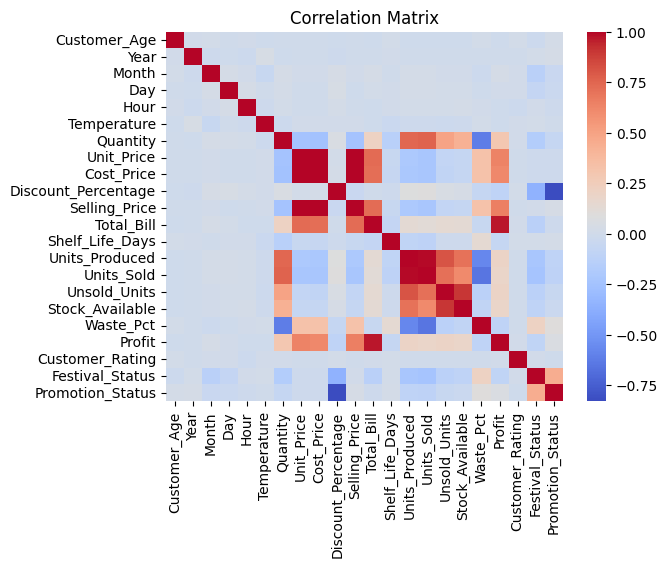

In [89]:
num_df = bake_df.select_dtypes(include='number')
corr_matrix = num_df.corr()
sns.heatmap(corr_matrix, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

There seems to be a lot of correlation with a columns that tend to explain a similar concept, the data goes to the granual level which could cause problems when modelling

## Current Data Fixes:
- Date: Object -> DateTime
- Weekend: Y/N -> T/F
- Columns: Hour [Keep] - Time [DROP] (Holds the same information)
- Discount Percentage: [NEW COLUMN] Discount (T/F)
- Promotion_Applied (Y/N) [DROP] - Promotion_Status (T/F) [KEEP]

## Current Questions
- What should I do about Unit_Price, Cost_Price, Discount_Percentage, Selling_price, Total_Bill (group)
- What should I do about Units_Produced, Units_Sold, Unsold_Units, Stock_Available (group)


There also seems to be a correlation with Teperature an certain columns, it would be interesting to explore!